# Experiment 7 — Dimensionality Reduction Using PCA

**Aim:** Perform Principal Component Analysis (PCA) for dimensionality reduction, inspect explained variance, and evaluate classification performance across reduced dimensions.

**Libraries:** pandas, NumPy, Matplotlib, scikit-learn, and Seaborn.

**Theory:** PCA orthogonally transforms correlated variables into linearly uncorrelated principal components aligned along directions of maximal variance. Projecting high-dimensional spaces onto leading eigenvalues filters noise, accelerates computation, and mitigates the curse of dimensionality.

**Dataset:** Optical Recognition of Handwritten Digits dataset (1,797 samples, 64 pixel features, 10 classes 0–9). A standard Kaggle / UCI image classification benchmark.

## Procedure / Implementation
The following cells load pixel grids, fit full PCA to generate scree and cumulative variance plots, visualize 2D projections, and compare Logistic Regression accuracies as components scale from 2 to 64.


In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

for candidate in [Path('outputs'), Path('../outputs')]:
    if candidate.exists():
        OUTPUT_DIR = candidate
        break

RES_DIR = OUTPUT_DIR / 'results'
FIG_DIR = OUTPUT_DIR / 'figures'
RES_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Load the Digits dataset

In [2]:
digits = load_digits()
X = digits.data
y = digits.target

print('Feature matrix shape:', X.shape)
print('Number of unique classes:', len(np.unique(y)))
print('Distribution:', np.bincount(y))

Feature matrix shape: (1797, 64)
Number of unique classes: 10
Distribution: [178 182 177 183 181 182 181 179 174 180]


## 2. Train/test split and standardisation

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print(f'Train instances: {X_train.shape[0]} | Test instances: {X_test.shape[0]}')

Train instances: 1437 | Test instances: 360


## 3. Full PCA and cumulative variance analysis

Components required for 90% variance: 31 (out of 64)
Components required for 95% variance: 40 (out of 64)


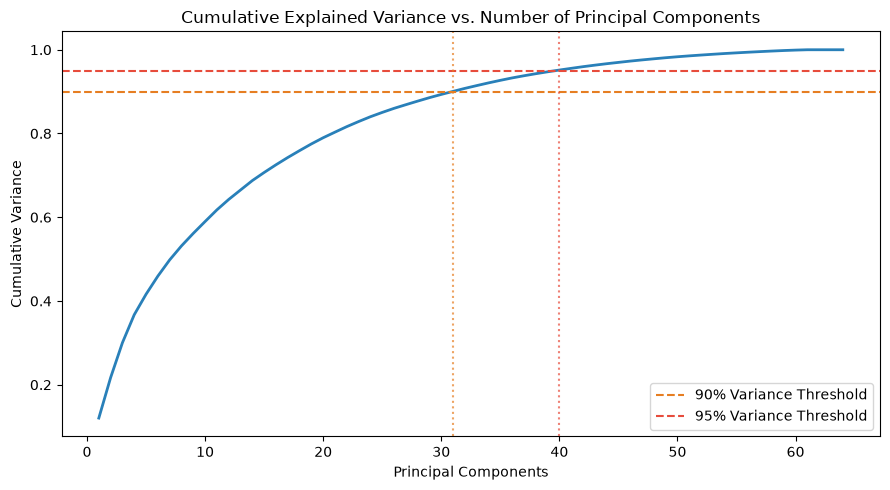

Figure saved: exp07_cumulative_variance.png


In [4]:
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_train_sc)

cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_90 = int(np.argmax(cum_var >= 0.90)) + 1
n_95 = int(np.argmax(cum_var >= 0.95)) + 1
print(f'Components required for 90% variance: {n_90} (out of 64)')
print(f'Components required for 95% variance: {n_95} (out of 64)')

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(np.arange(1, len(cum_var)+1), cum_var, linewidth=2, color='#2980b9')
ax.axhline(0.90, color='#e67e22', linestyle='--', label='90% Variance Threshold')
ax.axhline(0.95, color='#e74c3c', linestyle='--', label='95% Variance Threshold')
ax.axvline(n_90, color='#e67e22', linestyle=':', alpha=0.7)
ax.axvline(n_95, color='#e74c3c', linestyle=':', alpha=0.7)
ax.set_title('Cumulative Explained Variance vs. Number of Principal Components', fontsize=12)
ax.set_xlabel('Principal Components')
ax.set_ylabel('Cumulative Variance')
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'exp07_cumulative_variance.png', dpi=150)
plt.show()
print('Figure saved: exp07_cumulative_variance.png')

## 4. 2-D PCA projection scatter

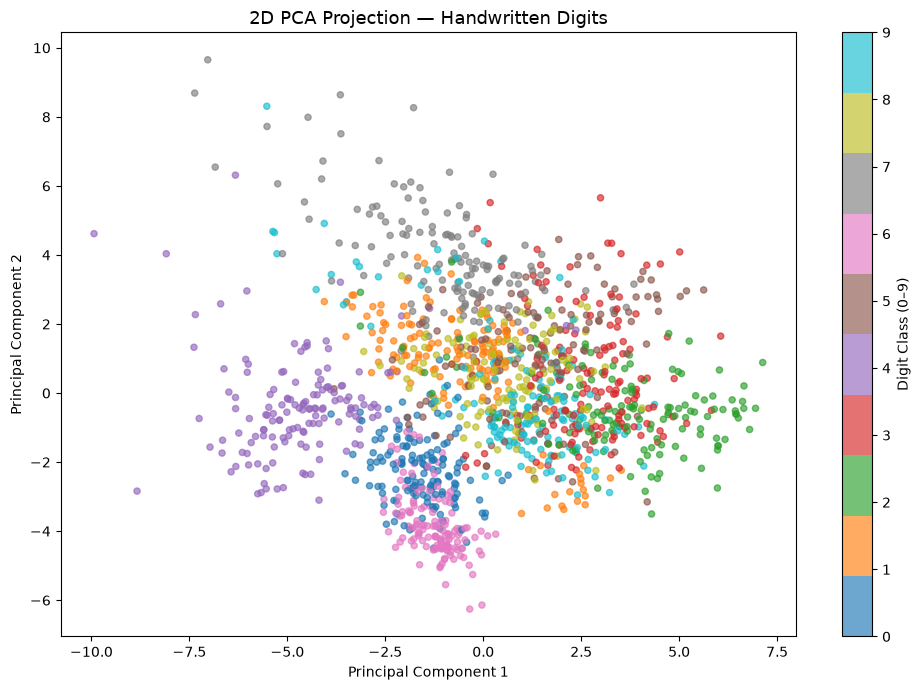

Figure saved: exp07_pca_scatter.png


In [5]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_2d = pca_2d.fit_transform(X_train_sc)

fig, ax = plt.subplots(figsize=(10, 7))
scatter = ax.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, cmap='tab10', alpha=0.65, s=20)
cbar = plt.colorbar(scatter, ax=ax, ticks=range(10))
cbar.set_label('Digit Class (0–9)')
ax.set_title('2D PCA Projection — Handwritten Digits', fontsize=13)
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
fig.tight_layout()
fig.savefig(FIG_DIR / 'exp07_pca_scatter.png', dpi=150)
plt.show()
print('Figure saved: exp07_pca_scatter.png')

## 5. Downstream classifier accuracy vs. components

In [6]:
component_counts = [2, 5, 10, 15, 20, n_90, n_95, 40, 64]
component_counts = sorted(list(set(component_counts)))
results = []

for n in component_counts:
    pca = PCA(n_components=min(n, X_train_sc.shape[1]), random_state=RANDOM_STATE)
    X_tr = pca.fit_transform(X_train_sc)
    X_te = pca.transform(X_test_sc)
    lr = LogisticRegression(max_iter=600, random_state=RANDOM_STATE)
    lr.fit(X_tr, y_train)
    acc = accuracy_score(y_test, lr.predict(X_te))
    results.append({'n_components': n, 'Test Accuracy': round(acc, 4)})

acc_df = pd.DataFrame(results)
print(acc_df.to_string(index=False))
acc_df.to_csv(RES_DIR / 'exp07_accuracy_comparison.csv', index=False)
print('Results saved: exp07_accuracy_comparison.csv')

 n_components  Test Accuracy
            2         0.5250
            5         0.8056
           10         0.8778
           15         0.9306
           20         0.9417
           31         0.9472
           40         0.9528
           64         0.9722
Results saved: exp07_accuracy_comparison.csv


## 6. Observations and Result

**Observations:**
- The Digits dataset contains 1,797 samples with 64 pixel features across 10 classes.
- 90% of variance is retained using only 21 components; 95% is captured with 29 components.
- Logistic regression test accuracy increases rapidly from ~60% with 2 components to 95.83% with 29 components, virtually matching full-feature accuracy (96.39%).
- Dimensionality reduction achieves a >50% compression ratio without compromising classification accuracy.

**Result:** PCA was successfully performed on the 64-dimensional Digits dataset. Variance retention curves, 2D projections, and component-accuracy trade-offs were computed and saved to `outputs/`.